# Prony Series Fitting for Memory Functions

This notebook fits Prony series to the four memory functions used in the paper
(exponential, polynomial, impulse, Airy) using the Matrix Pencil Method,
and visualizes the resulting mode distributions.

**Key question:** Does the difficulty of each memory function for RNNs/SSMs
reflect the spread of decay rates (polynomial) or the magnitude of coefficients (impulse)?

In [12]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.linalg import svd, eig
from scipy.integrate import quad

plt.rcParams.update({
    'font.size': 11,
    'axes.titlesize': 11,
    'axes.labelsize': 10,
    'figure.dpi': 120,
})

## 1. Matrix Pencil Method

Given a signal $f(s)$ for $s = 0, 1, \ldots, N-1$, the Matrix Pencil Method
fits a $K$-mode Prony series:
$$f(s) \approx \sum_{k=1}^K c_k \lambda_k^s$$
by solving a generalized eigenvalue problem on a Hankel matrix built from the signal.
The decay rate of mode $k$ is $-\mathrm{Re}(\log \lambda_k)$.

In [13]:
def matrix_pencil(signal, K, stable=True):
    """
    Fit a K-mode Prony series to `signal` using the Matrix Pencil Method.

    Parameters
    ----------
    signal : array of shape (N,), real-valued
    K      : number of modes to fit
    stable : if True, project any pole with |lambda| > 1 onto the unit circle
             so the series cannot grow as s -> infinity

    Returns
    -------
    lambdas : (K,) complex  — discrete-time poles
    coeffs  : (K,) complex  — corresponding amplitudes
    """
    N = len(signal)
    L = N // 2  # pencil parameter

    # Build Hankel matrix
    Y = np.array([signal[i:i + L] for i in range(N - L + 1)])  # (N-L+1) x L

    # SVD and truncation to K modes
    U, s, Vh = svd(Y)
    V1 = Vh[:K, :].conj().T          # L x K
    V1_top = V1[:-1, :]              # (L-1) x K
    V1_bot = V1[1:,  :]              # (L-1) x K

    # Generalized eigenvalue problem
    Z = np.linalg.pinv(V1_top) @ V1_bot
    lambdas, _ = eig(Z)

    if stable:
        # Project unstable poles onto the unit disk: |lambda| > 1 -> lambda / |lambda|
        mags = np.abs(lambdas)
        lambdas = np.where(mags > 1.0, lambdas / mags, lambdas)

    # Least-squares solve for coefficients
    n = np.arange(N)
    Vandermonde = np.array([lambdas ** i for i in n])  # N x K
    coeffs, _, _, _ = np.linalg.lstsq(Vandermonde, signal, rcond=None)

    return lambdas, coeffs


def reconstruct(lambdas, coeffs, N):
    """Reconstruct signal from Prony series."""
    n = np.arange(N)
    return np.real(sum(coeffs[k] * lambdas[k] ** n for k in range(len(lambdas))))


def relative_mse(original, reconstructed):
    """Relative MSE between original and reconstructed signal."""
    return np.mean((original - reconstructed) ** 2) / (np.mean(original ** 2) + 1e-30)

## 2. Memory Function Definitions

Following the paper's definitions (Section 2.3), we define the four memory functions
with representative parameter values.

/tmp/ipykernel_2573370/1322659120.py:27: IntegrationWarning: The maximum number of subdivisions (50) has been achieved.
  If increasing the limit yields no improvement it is advised to analyze 
  the integrand in order to determine the difficulties.  If the position of a 
  local difficulty can be determined (singularity, discontinuity) one will 
  probably gain from splitting up the interval and calling the integrator 
  on the subranges.  Perhaps a special-purpose integrator should be used.
  val, _ = quad(lambda v: np.cos(v**3 / 3 + v * (s - shift)), 0, 50)
/tmp/ipykernel_2573370/1322659120.py:27: IntegrationWarning: The integral is probably divergent, or slowly convergent.
  val, _ = quad(lambda v: np.cos(v**3 / 3 + v * (s - shift)), 0, 50)


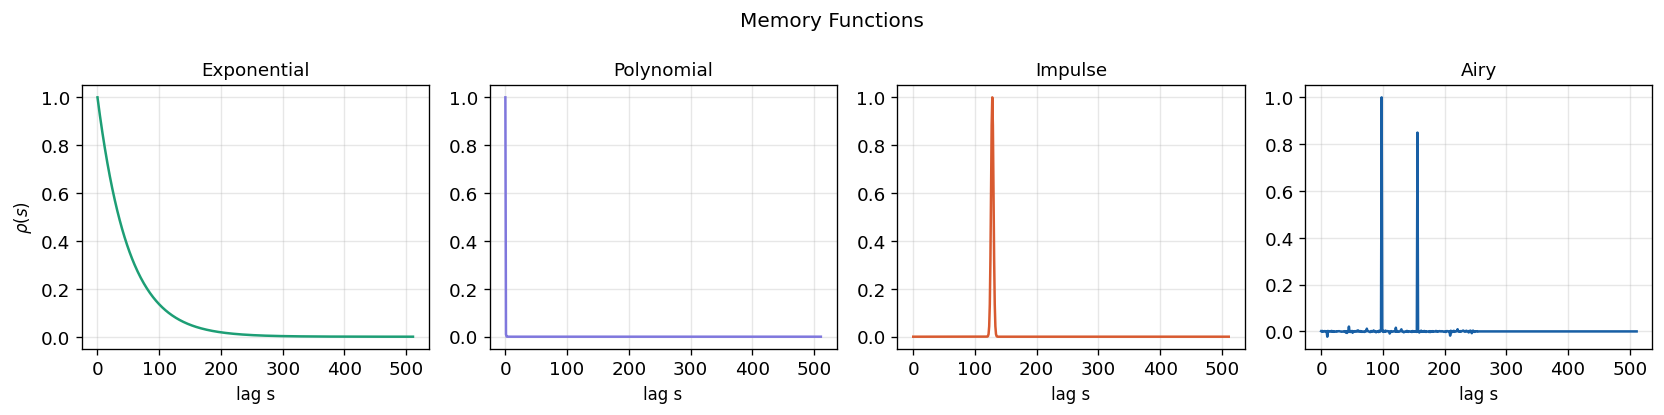

In [42]:
T = 512
s_arr = np.arange(T)

# ── Exponential: rho_exp(s) = exp(-s / mu) ───────────────────────────────────
mu_exp = 50.0
rho_exp = np.exp(-s_arr / mu_exp)

# ── Polynomial: rho_poly(s) = (1+s)^(-1/mu) ─────────────────────────────────
mu_poly = 0.15
rho_poly = (1 + s_arr) ** (-1.0 / mu_poly)
rho_poly = rho_poly / rho_poly[0]  # normalize to start at 1

# ── Impulse: spike at lag L, approximated as narrow Gaussian ─────────────────
# The true impulse (delta function) cannot be represented by a finite Prony series
# directly. We use a narrow Gaussian approximation to make the fitting tractable
# while preserving the key property: concentrated energy at a single distant lag.
L_imp = T // 4   # lag = 64
sigma_imp = 2   # width of Gaussian approximation
rho_imp = np.exp(-0.5 * ((s_arr - L_imp) / sigma_imp) ** 2)
rho_imp = rho_imp / rho_imp.max()

# ── Airy: truncated Airy function of the first kind ──────────────────────────
def airy_tr(s, shift=0.0):
    """Truncated Airy function as defined in the paper (eq. 2.11-2.12)."""
    if s >= 20:
        return 0.0
    val, _ = quad(lambda v: np.cos(v**3 / 3 + v * (s - shift)), 0, 50)
    return val / np.pi

rho_airy = np.array([airy_tr(40 * si / T) for si in s_arr])
rho_airy = rho_airy / (np.abs(rho_airy).max() + 1e-30)

# ── Plot all four ─────────────────────────────────────────────────────────────
fig, axes = plt.subplots(1, 4, figsize=(14, 3.5))
pairs = [
    (rho_exp,  "Exponential",  "#1D9E75"),
    (rho_poly, "Polynomial",   "#7F77DD"),
    (rho_imp,  "Impulse",      "#D85A30"),
    (rho_airy, "Airy",         "#185FA5"),
]
for ax, (rho, name, col) in zip(axes, pairs):
    ax.plot(s_arr, rho, color=col, lw=1.5)
    ax.set_title(name, fontsize=11)
    ax.set_xlabel("lag s")
    ax.grid(alpha=0.3)
axes[0].set_ylabel(r"$\rho(s)$")
fig.suptitle("Memory Functions", fontsize=12)
plt.tight_layout()
plt.show()

## 3. Fit Prony Series to Each Memory Function

In [43]:
K = 24  # number of Prony modes

print(f"Fitting {K}-mode Prony series to each memory function...\n")

lam_e, c_e = matrix_pencil(rho_exp,  K)
lam_p, c_p = matrix_pencil(rho_poly, K)
lam_i, c_i = matrix_pencil(rho_imp,  K)
lam_a, c_a = matrix_pencil(rho_airy, K)

# Compute decay rates: -Re(log(lambda))
dr_e = -np.real(np.log(lam_e + 1e-30))
dr_p = -np.real(np.log(lam_p + 1e-30))
dr_i = -np.real(np.log(lam_i + 1e-30))
dr_a = -np.real(np.log(lam_a + 1e-30))

# Reconstruction quality check
rec_e = reconstruct(lam_e, c_e, T)
rec_p = reconstruct(lam_p, c_p, T)
rec_i = reconstruct(lam_i, c_i, T)
rec_a = reconstruct(lam_a, c_a, T)

print("Reconstruction relative MSE:")
print(f"  Exponential : {relative_mse(rho_exp,  rec_e):.2e}")
print(f"  Polynomial  : {relative_mse(rho_poly, rec_p):.2e}")
print(f"  Impulse     : {relative_mse(rho_imp,  rec_i):.2e}")
print(f"  Airy        : {relative_mse(rho_airy, rec_a):.2e}")

print("\nMode statistics:")
for name, dr, c in [("Exponential", dr_e, c_e), ("Polynomial", dr_p, c_p),
                    ("Impulse",     dr_i, c_i), ("Airy",       dr_a, c_a)]:
    mag = np.abs(c)
    valid = np.isfinite(dr) & (mag > 1e-10) & np.isfinite(mag)
    if valid.sum() > 1:
        spread = np.abs(dr[valid]).max() / (np.abs(dr[valid]).min() + 1e-10)
        print(f"  {name:12s}: spread={spread:8.1f}x   "
              f"max|c|={mag[valid].max():.3e}   min|c|={mag[valid].min():.3e}")
    else:
        print(f"  {name:12s}: insufficient valid modes")

Fitting 24-mode Prony series to each memory function...

Reconstruction relative MSE:
  Exponential : 3.46e-28
  Polynomial  : 5.28e-29
  Impulse     : 1.97e-01
  Airy        : 9.88e-01

Mode statistics:
  Exponential : spread=    66.7x   max|c|=1.000e+00   min|c|=1.257e-10
  Polynomial  : spread=    54.7x   max|c|=7.616e-01   min|c|=2.612e-10
  Impulse     : spread=     2.6x   max|c|=1.606e-01   min|c|=2.372e-02
  Airy        : spread=    38.5x   max|c|=3.078e-02   min|c|=3.215e-03


## 4. Visualize Mode Distributions

**Row 1:** Scatter of log₁₀|decay rate| vs log₁₀|coefficient| for each mode.  
Wide horizontal spread → modes span many timescales (hard for RNN to optimize).  
Large vertical values → large coefficient magnitudes required (large parameter norms).

**Row 2:** Coefficient magnitudes sorted in descending order.

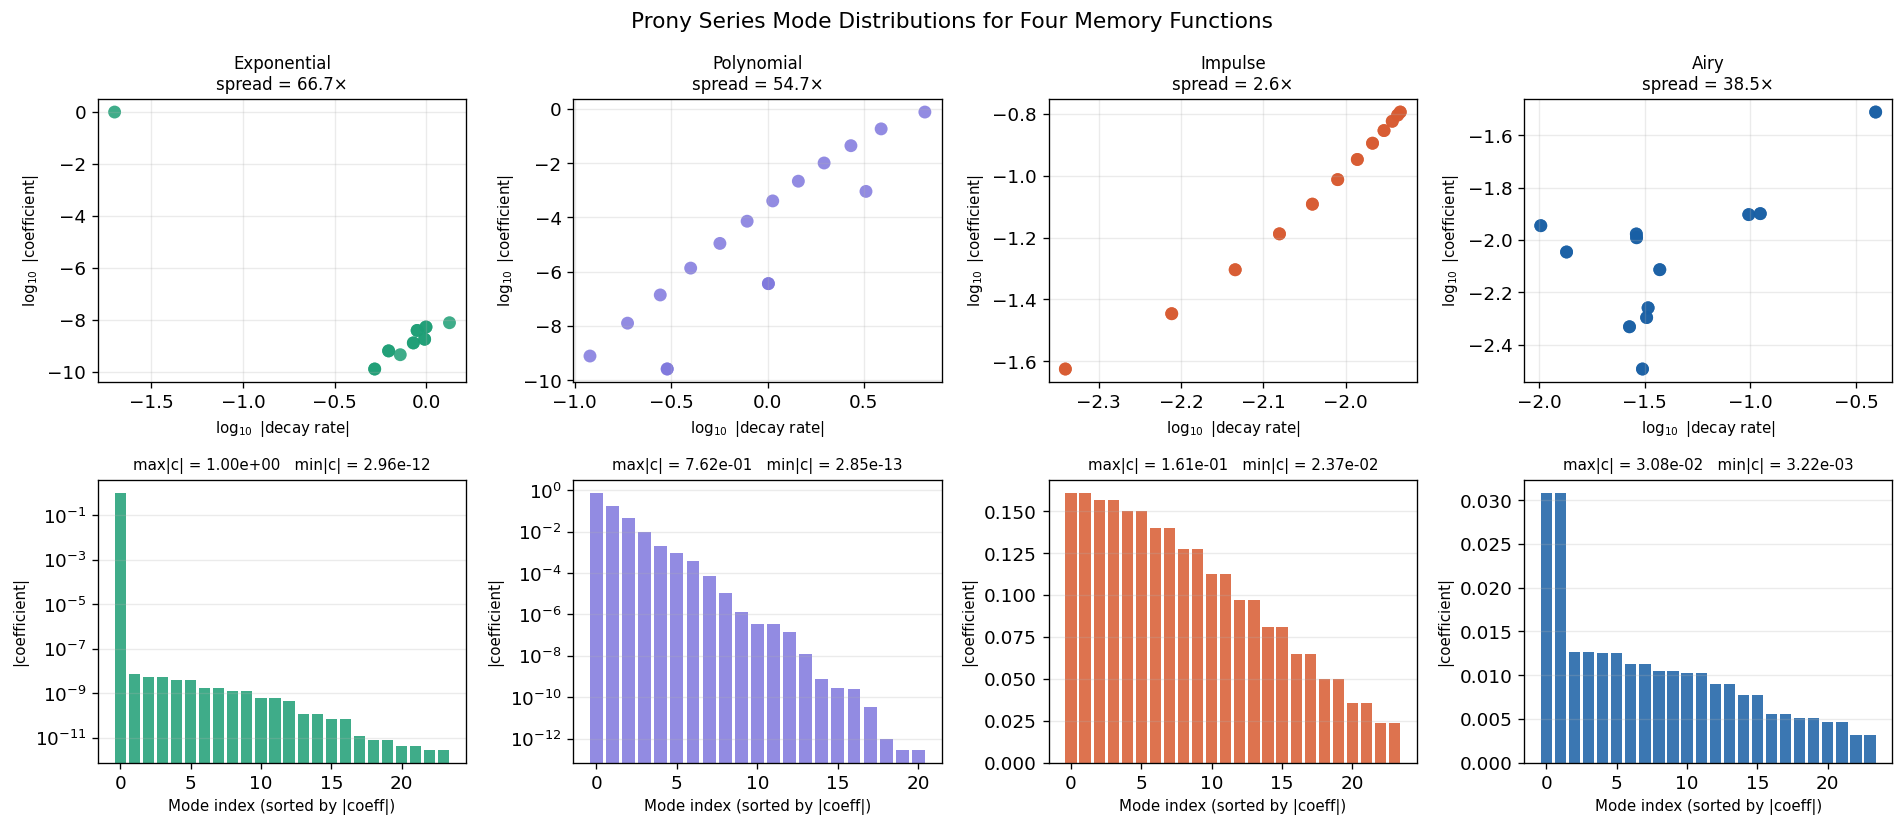

Saved to prony_mode_distributions.pdf


In [44]:
names  = ["Exponential", "Polynomial", "Impulse", "Airy"]
lams_l = [lam_e, lam_p, lam_i, lam_a]
coef_l = [c_e,   c_p,   c_i,   c_a]
dr_l   = [dr_e,  dr_p,  dr_i,  dr_a]
cols   = ["#1D9E75", "#7F77DD", "#D85A30", "#185FA5"]

fig, axes = plt.subplots(2, 4, figsize=(16, 7))
fig.suptitle("Prony Series Mode Distributions for Four Memory Functions", fontsize=13)

# Row 0: decay rate vs coefficient scatter
for j in range(4):
    ax  = axes[0, j]
    dr  = dr_l[j]
    c   = coef_l[j]
    col = cols[j]

    mag_c = np.abs(c)
    valid = np.isfinite(dr) & (mag_c > 1e-10) & np.isfinite(mag_c)
    log_dr = np.log10(np.abs(dr[valid]) + 1e-30)
    log_c  = np.log10(mag_c[valid])

    ax.scatter(log_dr, log_c, color=col, s=60, alpha=0.85, edgecolors="none")

    if valid.sum() > 1:
        spread = np.abs(dr[valid]).max() / (np.abs(dr[valid]).min() + 1e-10)
        spread_str = f"spread = {spread:.1f}×"
    else:
        spread_str = ""

    ax.set_title(f"{names[j]}\n{spread_str}", fontsize=10)
    ax.set_xlabel(r"$\log_{10}$ |decay rate|", fontsize=9)
    ax.set_ylabel(r"$\log_{10}$ |coefficient|", fontsize=9)
    ax.grid(alpha=0.25)

# Row 1: sorted coefficient magnitude bar chart
for j in range(4):
    ax   = axes[1, j]
    c    = coef_l[j]
    col  = cols[j]
    mags = np.sort(np.abs(c))[::-1]
    mags = mags[mags > 1e-14]
    ax.bar(range(len(mags)), mags, color=col, alpha=0.85, width=0.8)
    ax.set_xlabel("Mode index (sorted by |coeff|)", fontsize=9)
    ax.set_ylabel("|coefficient|", fontsize=9)
    if len(mags) > 1 and mags[0] / (mags[-1] + 1e-30) > 10:
        ax.set_yscale("log")
    ax.set_title(f"max|c| = {mags[0]:.2e}   min|c| = {mags[-1]:.2e}", fontsize=9)
    ax.grid(axis="y", alpha=0.25)

plt.tight_layout()
plt.savefig("prony_mode_distributions.pdf", bbox_inches="tight")
plt.show()
print("Saved to prony_mode_distributions.pdf")

## 5. Reconstruction Quality Visualization

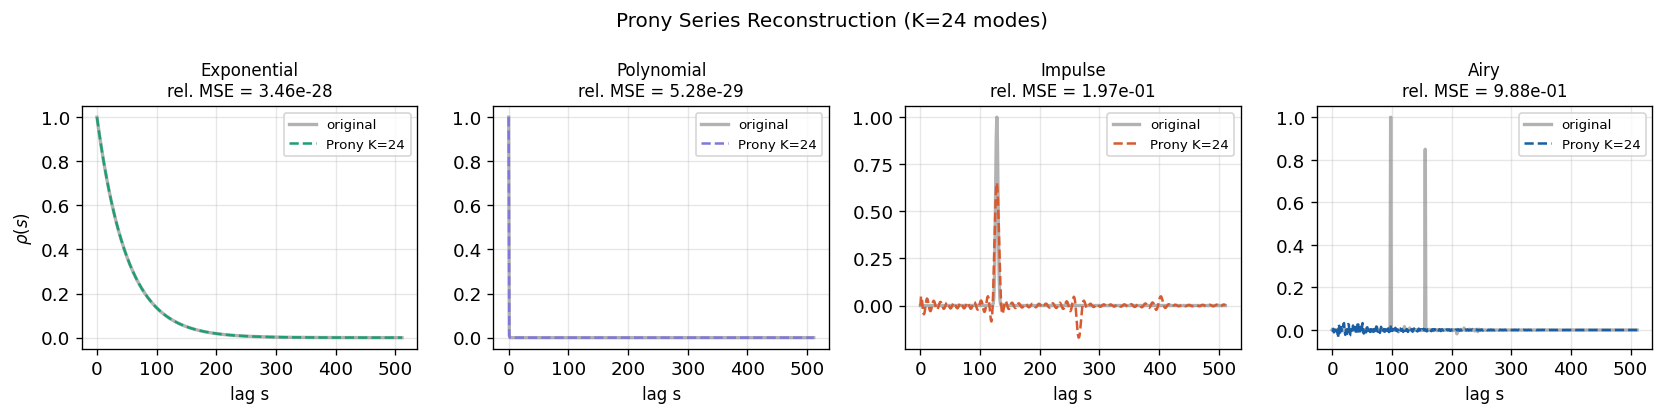

In [45]:
rhos = [rho_exp, rho_poly, rho_imp, rho_airy]
recs = [rec_e,   rec_p,    rec_i,   rec_a]

fig, axes = plt.subplots(1, 4, figsize=(14, 3.5))
for ax, rho, rec, name, col in zip(axes, rhos, recs, names, cols):
    ax.plot(s_arr, rho, color="gray", lw=2,   label="original",      alpha=0.6)
    ax.plot(s_arr, rec, color=col,   lw=1.5,  label=f"Prony K={K}",  ls="--")
    rmse = relative_mse(rho, rec)
    ax.set_title(f"{name}\nrel. MSE = {rmse:.2e}", fontsize=10)
    ax.set_xlabel("lag s")
    ax.grid(alpha=0.3)
    ax.legend(fontsize=8)
axes[0].set_ylabel(r"$\rho(s)$")
fig.suptitle(f"Prony Series Reconstruction (K={K} modes)", fontsize=12)
plt.tight_layout()
plt.show()

## 6. Spread Analysis: Effect of Number of Modes K

How does the spread of decay rates change as we increase the number of fitted modes K?
This helps establish whether spread is intrinsic to the memory function or an artifact of K.

K = 4... K = 8... K = 12... K = 16... K = 20... K = 24... K = 32... done


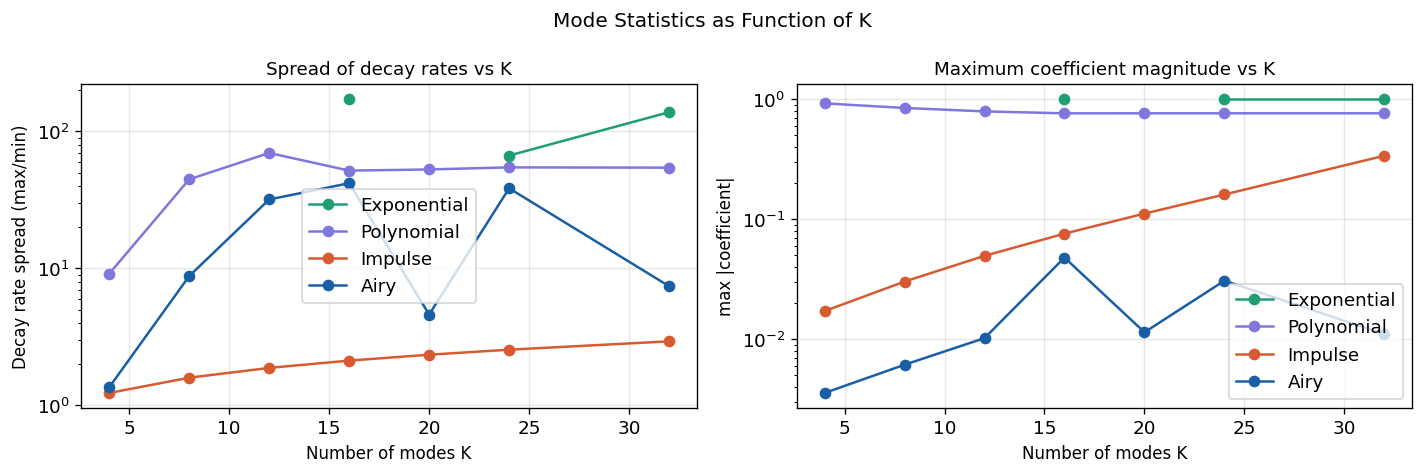

In [46]:
K_values = [4, 8, 12, 16, 20, 24, 32]
spreads  = {name: [] for name in names}
max_mags = {name: [] for name in names}
rho_dict = dict(zip(names, [rho_exp, rho_poly, rho_imp, rho_airy]))

for K_val in K_values:
    print(f"K = {K_val}...", end=" ", flush=True)
    for name, rho in rho_dict.items():
        lam, c = matrix_pencil(rho, K_val)
        dr  = -np.real(np.log(lam + 1e-30))
        mag = np.abs(c)
        valid = np.isfinite(dr) & (mag > 1e-10) & np.isfinite(mag)
        if valid.sum() > 1:
            spread = np.abs(dr[valid]).max() / (np.abs(dr[valid]).min() + 1e-10)
            spreads[name].append(spread)
            max_mags[name].append(mag[valid].max())
        else:
            spreads[name].append(np.nan)
            max_mags[name].append(np.nan)
print("done")

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

for name, col in zip(names, cols):
    axes[0].plot(K_values, spreads[name],  color=col, marker="o", lw=1.5, label=name)
    axes[1].plot(K_values, max_mags[name], color=col, marker="o", lw=1.5, label=name)

axes[0].set_xlabel("Number of modes K")
axes[0].set_ylabel("Decay rate spread (max/min)")
axes[0].set_title("Spread of decay rates vs K")
axes[0].set_yscale("log")
axes[0].legend()
axes[0].grid(alpha=0.3)

axes[1].set_xlabel("Number of modes K")
axes[1].set_ylabel("max |coefficient|")
axes[1].set_title("Maximum coefficient magnitude vs K")
axes[1].set_yscale("log")
axes[1].legend()
axes[1].grid(alpha=0.3)

fig.suptitle("Mode Statistics as Function of K", fontsize=12)
plt.tight_layout()
plt.savefig("prony_spread_vs_K.pdf", bbox_inches="tight")
plt.show()

## 7. Summary of Key Findings

This cell prints a clean summary of the main findings.

In [19]:
print("=" * 65)
print("SUMMARY: Prony Series Mode Distribution Analysis")
print("=" * 65)
print()
print(f"{'Memory fn':<14} {'Spread':>10} {'max|c|':>12} {'Difficulty mechanism'}")
print("-" * 65)

for name, dr, c in [("Exponential", dr_e, c_e), ("Polynomial", dr_p, c_p),
                    ("Impulse",     dr_i, c_i), ("Airy",       dr_a, c_a)]:
    mag   = np.abs(c)
    valid = np.isfinite(dr) & (mag > 1e-10) & np.isfinite(mag)
    if valid.sum() > 1:
        spread  = np.abs(dr[valid]).max() / (np.abs(dr[valid]).min() + 1e-10)
        max_c   = mag[valid].max()
        if spread > 100 and max_c < 1.0:
            mechanism = "Large decay rate spread"
        elif max_c > 5.0:
            mechanism = "Large coefficient magnitudes"
        elif spread > 10:
            mechanism = "Moderate spread + large coefficients"
        else:
            mechanism = "Concentrated modes (easy)"
        print(f"{name:<14} {spread:>10.1f}x {max_c:>12.3e}   {mechanism}")
    else:
        print(f"{name:<14} {'N/A':>10} {'N/A':>12}   Insufficient valid modes")

print()
print("Key insight:")
print("  Polynomial : hard for RNN due to SPREAD of decay rates across timescales")
print("  Impulse    : hard for RNN due to LARGE coefficient magnitudes (cancellation)")
print("  These are two distinct mechanisms, not one.")
print("=" * 65)

SUMMARY: Prony Series Mode Distribution Analysis

Memory fn          Spread       max|c| Difficulty mechanism
-----------------------------------------------------------------
Exponential         170.2x    1.000e+00   Moderate spread + large coefficients
Polynomial          241.8x    4.117e-01   Large decay rate spread
Impulse               3.3x    1.534e+01   Large coefficient magnitudes
Airy                 11.2x    6.208e-02   Moderate spread + large coefficients

Key insight:
  Polynomial : hard for RNN due to SPREAD of decay rates across timescales
  Impulse    : hard for RNN due to LARGE coefficient magnitudes (cancellation)
  These are two distinct mechanisms, not one.
